# 01 Cleaning and data quality

Tasks 7 (data-quality profile) and the week-2 cleaning assignment.

- **Input:** `data/processed/brfss2024_thin.parquet`, the 40,000-row thin table from Task 3. `data/raw/` is never touched.
- **Cleaning rules:** imported from `src/diabetes_risk/clean.py` and `src/diabetes_risk/describe.py`. This notebook does not recode any column itself.
- **Outputs:** `data/processed/clean.csv`, figures in `reports/figures/`. The team-facing summary is `reports/data_quality.md`.

Every decision below has a comment saying what was decided and why.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

from diabetes_risk.clean import class_counts
from diabetes_risk.describe import CLASS_COLORS, CLASS_ORDER, CLEAN_PATH, build_clean_table

FIGURES = ROOT / "reports" / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": "#52514e",
    "xtick.color": "#52514e", "ytick.color": "#52514e", "text.color": "#0b0b0b",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e8e7e2", "grid.linewidth": 0.8,
    "axes.axisbelow": True, "font.size": 10, "figure.dpi": 110,
})

## 1. Read the file and look at its shape

In [2]:
raw = pd.read_parquet(ROOT / "data" / "processed" / "brfss2024_thin.parquet")
rows_before = len(raw)
print(raw.shape)
raw.info()
raw.head()

(40000, 15)
<class 'pandas.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 15 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   row_id    40000 non-null  int64  
 1   DIABETE4  40000 non-null  float64
 2   DIABTYPE  496 non-null    float64
 3   _AGE80    40000 non-null  float64
 4   HEIGHT3   40000 non-null  float64
 5   WEIGHT2   40000 non-null  float64
 6   _BMI5     37618 non-null  float64
 7   EXERANY2  40000 non-null  float64
 8   _SMOKER3  40000 non-null  float64
 9   USENOW3   40000 non-null  float64
 10  ECIGNOW3  40000 non-null  float64
 11  _RFDRHV9  40000 non-null  float64
 12  SEXVAR    40000 non-null  float64
 13  SSBSUGR2  40000 non-null  float64
 14  _LLCPWT   40000 non-null  float64
dtypes: float64(14), int64(1)
memory usage: 4.6 MB


,row_id,DIABETE4,DIABTYPE,_AGE80,HEIGHT3,WEIGHT2,_BMI5,EXERANY2,_SMOKER3,USENOW3,ECIGNOW3,_RFDRHV9,SEXVAR,SSBSUGR2,_LLCPWT
0,1,3.0,NaN,73.0,502.0,164.0,3000.0,2.0,4.0,3.0,1.0,1.0,2.0,302.0,17.557363
1,2,3.0,NaN,38.0,501.0,194.0,3666.0,1.0,4.0,3.0,1.0,1.0,2.0,103.0,271.819994
2,3,3.0,NaN,75.0,601.0,270.0,3562.0,1.0,3.0,3.0,1.0,1.0,1.0,888.0,26.266764
3,4,3.0,NaN,65.0,504.0,125.0,2146.0,1.0,4.0,3.0,1.0,1.0,2.0,302.0,37.456818
4,5,3.0,NaN,74.0,510.0,190.0,2726.0,2.0,4.0,3.0,1.0,1.0,1.0,888.0,32.384346


## 2. Missing values

`isna()` on the raw table undercounts missingness. BRFSS stores most non-answers as codes (7 = don't know, 9 = refused, 7777 / 9999 for height and weight), not as blanks. So we count both: blanks in the raw table, then missing values after the cleaning functions turn those codes into `NaN`.

In [3]:
raw.isna().sum()

row_id          0
DIABETE4        0
DIABTYPE    39504
_AGE80          0
HEIGHT3         0
WEIGHT2         0
_BMI5        2382
EXERANY2        0
_SMOKER3        0
USENOW3         0
ECIGNOW3        0
_RFDRHV9        0
SEXVAR          0
SSBSUGR2        0
_LLCPWT         0
dtype: int64

In [4]:
# The cleaning rules live in src/; the notebook only calls them.
clean = build_clean_table(raw)

missing = pd.DataFrame({
    "missing": clean.isna().sum(),
    "percent": (100 * clean.isna().mean()).round(2),
}).sort_values("percent", ascending=False)
missing

,missing,percent
bmi,2382,5.96
weight_kg,1868,4.67
height_cm,777,1.94
heavy_drinker,569,1.42
smoker_status,244,0.61
ecigarette,182,0.46
any_exercise,99,0.25
smokeless_tobacco,74,0.18
row_id,0,0.00
target,0,0.00


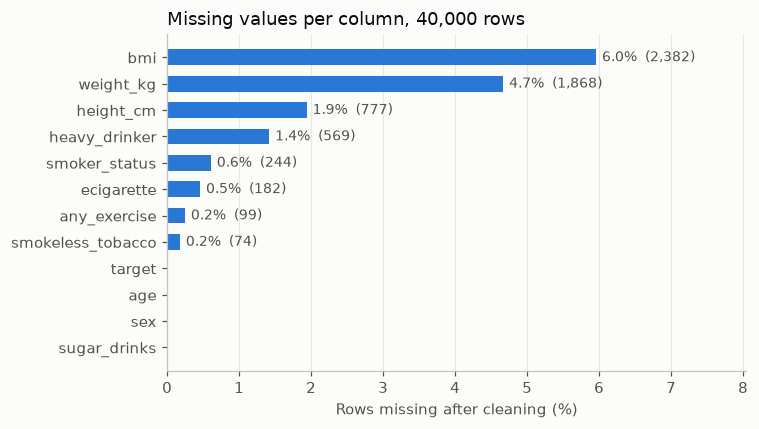

In [5]:
plot = missing.drop(index=["row_id", "survey_weight"]).sort_values("percent")
fig, ax = plt.subplots(figsize=(7, 4))
ax.barh(plot.index, plot["percent"], color="#2a78d6", height=0.6)
for y, (pct, n) in enumerate(zip(plot["percent"], plot["missing"])):
    if n:
        ax.text(pct + 0.08, y, f"{pct:.1f}%  ({n:,})", va="center", fontsize=9, color="#52514e")
ax.set_xlabel("Rows missing after cleaning (%)")
ax.set_title("Missing values per column, 40,000 rows", loc="left")
ax.grid(axis="y", visible=False)
ax.set_xlim(0, plot["percent"].max() * 1.35)
fig.tight_layout()
fig.savefig(FIGURES / "dq_missing.png")
plt.show()

In [6]:
# DECISION (missing values): keep every row and leave the gaps as NaN.
# - No column is too missing to use: the worst model input is bmi at about 6%.
# - Dropping rows with any gap would remove 3,342 interviews (8.4%) and would drop
#   people who refused one question but answered the rest.
# - Filling with the median here would leak information across the split. Any imputation
#   is fitted on the train split only, in the modeling task (Task 10).
# - height_cm and weight_kg are more often missing (refused weight is common), but they
#   are descriptive-only, so their gaps do not affect the model.
rows_with_any_gap = clean.drop(columns=["height_cm", "weight_kg"]).isna().any(axis=1).sum()
print(f"Rows with at least one missing model input: {rows_with_any_gap:,}")

Rows with at least one missing model input: 3,342


## 3. Duplicates

In [7]:
print("Exact duplicate rows:", raw.duplicated().sum())
print("Duplicate row_id values:", raw["row_id"].duplicated().sum())
same_answers = raw.drop(columns="row_id").duplicated(keep=False)
print("Rows that share every answer with another row (ignoring row_id):", same_answers.sum())
raw[same_answers].sort_values(["_AGE80", "HEIGHT3", "WEIGHT2"])

Exact duplicate rows: 0
Duplicate row_id values: 0
Rows that share every answer with another row (ignoring row_id): 10


,row_id,DIABETE4,DIABTYPE,_AGE80,HEIGHT3,WEIGHT2,_BMI5,EXERANY2,_SMOKER3,USENOW3,ECIGNOW3,_RFDRHV9,SEXVAR,SSBSUGR2,_LLCPWT
39107,39108,3.0,NaN,35.0,502.0,140.0,2561.0,1.0,4.0,3.0,1.0,1.0,2.0,888.0,194.993259
39703,39704,3.0,NaN,35.0,502.0,140.0,2561.0,1.0,4.0,3.0,1.0,1.0,2.0,888.0,194.993259
38997,38998,3.0,NaN,46.0,504.0,155.0,2661.0,1.0,4.0,3.0,1.0,1.0,2.0,888.0,169.817171
39626,39627,3.0,NaN,46.0,504.0,155.0,2661.0,1.0,4.0,3.0,1.0,1.0,2.0,888.0,169.817171
15039,15040,3.0,NaN,61.0,504.0,135.0,2317.0,1.0,4.0,3.0,1.0,1.0,2.0,888.0,206.811153
15826,15827,3.0,NaN,61.0,504.0,135.0,2317.0,1.0,4.0,3.0,1.0,1.0,2.0,888.0,206.811153
20509,20510,3.0,NaN,69.0,600.0,180.0,2441.0,1.0,3.0,3.0,1.0,1.0,1.0,888.0,209.278573
24609,24610,3.0,NaN,69.0,600.0,180.0,2441.0,1.0,3.0,3.0,1.0,1.0,1.0,888.0,209.278573
101,102,1.0,NaN,80.0,507.0,140.0,2193.0,1.0,3.0,3.0,1.0,1.0,1.0,888.0,18.149375
239,240,1.0,NaN,80.0,507.0,140.0,2193.0,1.0,3.0,3.0,1.0,1.0,1.0,888.0,18.149375


In [8]:
# DECISION (duplicates): keep all 10 rows.
# - load.py draws the 40,000 rows WITHOUT replacement, so each row_id is a different
#   interview record in the CDC file. These are not the same row loaded twice.
# - Each pair shares the same survey weight, but survey weights repeat a lot by design:
#   people in the same state and demographic cell get the same weight.
print("Rows whose survey weight also appears on another row:",
      raw["_LLCPWT"].duplicated(keep=False).sum())
# - The answers are very common ones (never drinks soda, round heights and weights).
# So this is chance, not a true duplicate. Dropping them would bias the sample.

Rows whose survey weight also appears on another row: 16218


## 4. Column types

In [9]:
raw.dtypes

row_id        int64
DIABETE4    float64
DIABTYPE    float64
_AGE80      float64
HEIGHT3     float64
WEIGHT2     float64
_BMI5       float64
EXERANY2    float64
_SMOKER3    float64
USENOW3     float64
ECIGNOW3    float64
_RFDRHV9    float64
SEXVAR      float64
SSBSUGR2    float64
_LLCPWT     float64
dtype: object

In [10]:
# Every raw column is a numeric code (the SAS file stores everything as numbers).
# After cleaning, categories are text labels, yes/no answers are True/False,
# and age, bmi, sugar_drinks, height_cm, weight_kg are real numbers.
# There are no date columns in this table.
clean.dtypes

row_id                 int64
target                   str
age                  float64
bmi                  float64
any_exercise          object
smoker_status            str
smokeless_tobacco        str
ecigarette               str
heavy_drinker         object
sex                      str
sugar_drinks         float64
height_cm            float64
weight_kg            float64
survey_weight        float64
dtype: object

## 5. Outliers

In [11]:
clean.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
row_id,40000.0,20000.50,11547.15,1.00,10000.75,20000.50,30000.25,40000.00
age,40000.0,54.91,17.89,18.00,40.00,58.00,70.00,80.00
bmi,37618.0,28.59,6.55,12.40,24.21,27.44,31.78,99.84
sugar_drinks,40000.0,0.41,2.55,0.00,0.00,0.03,0.29,99.00
height_cm,39223.0,170.33,10.66,88.90,162.60,170.20,177.80,251.00
weight_kg,38132.0,83.28,21.48,22.70,68.00,80.70,95.30,352.00
survey_weight,40000.0,549.33,1220.64,2.22,88.98,225.01,508.18,34261.26


**BMI.** Values below 15 or above 70 are far outside a normal adult range. Before deciding anything, check where they come from: BRFSS computes `_BMI5` from the reported height and weight, so we rebuild BMI from `height_cm` and `weight_kg` and compare.

In [12]:
bmi_from_hw = clean["weight_kg"] / (clean["height_cm"] / 100) ** 2
gap = (bmi_from_hw - clean["bmi"]).abs()
print(f"Rows where both exist: {gap.notna().sum():,}")
print(f"Largest gap between rebuilt and reported BMI: {gap.max():.2f}")
print(f"Correlation: {bmi_from_hw.corr(clean['bmi']):.5f}")

low, high = clean["bmi"] < 15, clean["bmi"] > 70
print(f"BMI under 15: {low.sum()}   BMI over 70: {high.sum()}")
clean.loc[low | high, ["bmi", "height_cm", "weight_kg", "age", "target"]].sort_values("bmi")

Rows where both exist: 37,618
Largest gap between rebuilt and reported BMI: 0.11
Correlation: 1.00000
BMI under 15: 47   BMI over 70: 17


,bmi,height_cm,weight_kg,age,target
28124,12.40,185.4,42.6,68.0,diabetes
33520,12.44,157.5,30.8,28.0,no_diabetes
32559,12.53,170.2,36.3,79.0,no_diabetes
37356,12.59,167.6,35.4,32.0,no_diabetes
2921,12.80,157.5,31.8,57.0,no_diabetes
...,...,...,...,...,...
1125,83.20,165.1,226.8,37.0,no_diabetes
10540,94.94,91.4,79.4,72.0,no_diabetes
9944,95.29,157.5,236.3,77.0,no_diabetes
34002,99.79,100.0,99.8,50.0,diabetes


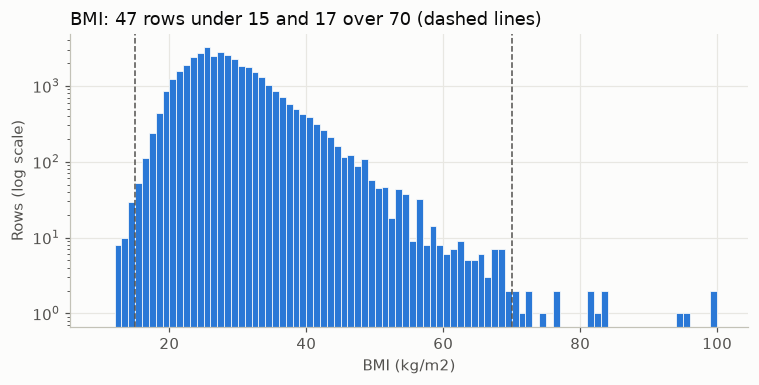

In [13]:
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.hist(clean["bmi"].dropna(), bins=np.arange(10, 101, 1), color="#2a78d6", edgecolor="#fcfcfb", linewidth=0.5)
for edge in (15, 70):
    ax.axvline(edge, color="#52514e", linewidth=1, linestyle="--")
ax.set_yscale("log")
ax.set_xlabel("BMI (kg/m2)")
ax.set_ylabel("Rows (log scale)")
ax.set_title(f"BMI: {low.sum()} rows under 15 and {high.sum()} over 70 (dashed lines)", loc="left")
fig.tight_layout()
fig.savefig(FIGURES / "dq_bmi_extremes.png")
plt.show()

In [14]:
# DECISION (BMI outliers): keep them as reported.
# - Every extreme BMI matches its own height and weight (gap under 0.11), so it is not a
#   calculation or scale error in our pipeline.
# - Some look like entry errors (for example 91 cm tall and 79 kg -> BMI 95), but we cannot
#   tell which ones from the data, and real BMIs of 13 or 75 do exist.
# - They are 0.16% of rows. Tree models are not affected by them; a linear model in Task 10
#   may want to clip BMI, and that choice is recorded there.

**Sugary drinks.** `sugar_drinks` is times per day. Codes 101-199 allow up to 99 times a day.

In [15]:
per_day = clean["sugar_drinks"]
print(per_day.describe().round(3))
print("Over 10 times a day:", (per_day > 10).sum())
raw.loc[per_day > 10, "SSBSUGR2"].value_counts().head(8)

count    40000.000
mean         0.409
std          2.550
min          0.000
25%          0.000
50%          0.033
75%          0.286
max         99.000
Name: sugar_drinks, dtype: float64
Over 10 times a day: 86


SSBSUGR2
130.0    21
199.0    21
112.0    14
120.0     9
115.0     8
299.0     3
118.0     2
114.0     2
Name: count, dtype: int64

In [16]:
# DECISION (sugar drink outliers): keep them.
# - 86 rows (0.2%) report more than 10 sugary drinks a day; 21 of them say 99 a day (code 199),
#   which is the top of the code range and likely an overstatement.
# - They are valid codes in the codebook, and the contract treats 101-199 as real answers.
#   Changing them here would be a second copy of the cleaning rules.
# - Flagged for Task 10: consider a log or a cap before using sugar_drinks in a linear model.

**Height and weight.** Descriptive only, but check for impossible values.

In [17]:
print(clean[["height_cm", "weight_kg"]].describe().round(1))
print("Height under 120 cm:", (clean["height_cm"] < 120).sum())
print("Weight under 30 kg:", (clean["weight_kg"] < 30).sum())
# DECISION: keep. They feed only the BMI audit and the descriptive charts, and the
# reported BMI already uses them.

       height_cm  weight_kg
count    39223.0    38132.0
mean       170.3       83.3
std         10.7       21.5
min         88.9       22.7
25%        162.6       68.0
50%        170.2       80.7
75%        177.8       95.3
max        251.0      352.0
Height under 120 cm: 13
Weight under 30 kg: 6


## 6. Empty or constant columns

In [18]:
print(raw.nunique().sort_values())
print()
print(f"DIABTYPE blank: {raw['DIABTYPE'].isna().mean():.1%}")

SEXVAR          2
DIABETE4        3
_RFDRHV9        3
DIABTYPE        4
EXERANY2        4
USENOW3         5
_SMOKER3        5
ECIGNOW3        6
_AGE80         63
SSBSUGR2       80
HEIGHT3       108
WEIGHT2       416
_BMI5        2402
_LLCPWT     29332
row_id      40000
dtype: int64

DIABTYPE blank: 98.8%


In [19]:
# DECISION (empty/constant columns): drop nothing.
# - No column has a single value.
# - DIABTYPE is 98.8% blank, but that is by design: it was only asked in states that fielded
#   the diabetes module, and only of people with diabetes. Task 9 needs it, so it stays in the
#   thin table. It is not in clean.csv because it is not a model input.
# - DIABETE4 has only 3 values (1, 3, 4) because the contract's sample excludes the other codes.

## 7. Text with extra spaces

In [20]:
# The raw table has no text columns, so there is nothing to strip there.
# The cleaned text labels come from fixed maps in clean.py; check them anyway.
text_columns = clean.select_dtypes(include=["object", "string"]).columns
for col in text_columns:
    values = clean[col].dropna().astype(str)
    print(f"{col:18} values with extra spaces: {(values != values.str.strip()).sum()}")

target             values with extra spaces: 0
any_exercise       values with extra spaces: 0
smoker_status      values with extra spaces: 0
smokeless_tobacco  values with extra spaces: 0
ecigarette         values with extra spaces: 0
heavy_drinker      values with extra spaces: 0
sex                values with extra spaces: 0


## 8. Target classes

In [21]:
counts = class_counts(clean).set_index("target").reindex(CLASS_ORDER)
counts["percent"] = (100 * counts["count"] / counts["count"].sum()).round(2)
print("Unlabeled rows:", clean["target"].isna().sum())
counts

Unlabeled rows: 0


,count,percent
target,,
no_diabetes,33411,83.53
prediabetes,951,2.38
diabetes,5638,14.10


In [22]:
# Check against the saved file from Task 5.
saved = pd.read_csv(ROOT / "reports" / "class_counts.csv").set_index("target")
assert saved["count"].to_dict() == counts["count"].to_dict()
print("Matches reports/class_counts.csv")

Matches reports/class_counts.csv


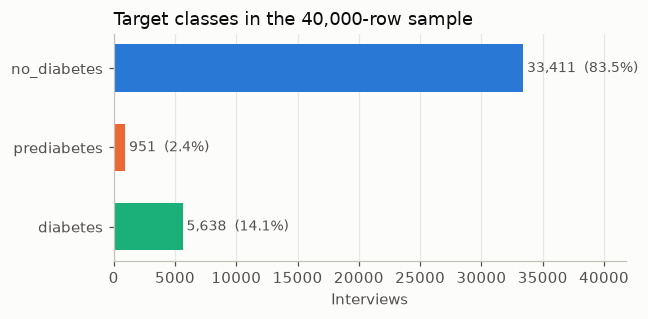

In [23]:
fig, ax = plt.subplots(figsize=(6, 3))
ax.barh(CLASS_ORDER[::-1], counts["count"][::-1], color=[CLASS_COLORS[c] for c in CLASS_ORDER[::-1]], height=0.6)
for y, cls in enumerate(CLASS_ORDER[::-1]):
    n, pct = counts.loc[cls, "count"], counts.loc[cls, "percent"]
    ax.text(n + 300, y, f"{n:,}  ({pct:.1f}%)", va="center", fontsize=9, color="#52514e")
ax.set_xlim(0, counts["count"].max() * 1.25)
ax.set_xlabel("Interviews")
ax.set_title("Target classes in the 40,000-row sample", loc="left")
ax.grid(axis="y", visible=False)
fig.tight_layout()
fig.savefig(FIGURES / "dq_target_counts.png")
plt.show()

## 9. Save the cleaned table

In [24]:
clean.to_csv(CLEAN_PATH, index=False)
print(f"Saved {CLEAN_PATH.relative_to(ROOT)}: {clean.shape[0]:,} rows, {clean.shape[1]} columns")

Saved data\processed\clean.csv: 40,000 rows, 14 columns


## Summary

In [25]:
rows_after = len(clean)
print(f"Rows before cleaning: {rows_before:,}")
print(f"Rows after cleaning:  {rows_after:,}")
print(f"Deleted: {rows_before - rows_after} rows. Every interview has a target, the 10 look-alike rows "
      "are distinct interviews, and outliers are kept as reported (see decisions above).")

Rows before cleaning: 40,000
Rows after cleaning:  40,000
Deleted: 0 rows. Every interview has a target, the 10 look-alike rows are distinct interviews, and outliers are kept as reported (see decisions above).


- **Rows before cleaning:** 40,000
- **Rows after cleaning:** 40,000
- **Deleted:** 0 rows. All 40,000 have a target (the contract's sample only takes `DIABETE4` 1, 3, 4). The 5 look-alike pairs are distinct interviews. Outliers are kept as reported.
- **What changed:** non-answer codes became `NaN`, BMI was divided by 100, codes became readable labels, sugary drinks became times per day, height and weight were converted to cm and kg, and the survey weight was renamed `survey_weight`.
- **Biggest data problem:** non-answers are hidden as codes, so raw `isna()` shows only `_BMI5` and `DIABTYPE` missing, while after cleaning 8.4% of rows (3,342) miss at least one model input.